In [1]:
import io
import math
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from google.colab import files
from torchvision.models import resnet18, ResNet18_Weights

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Urządzenie:", device)


Urządzenie: cuda


Saving a.png to a.png
Plik: a.png Rozmiar: (900, 533) Tensor: (1, 1, 533, 900)


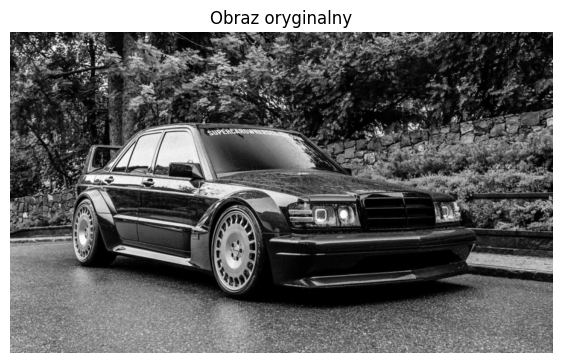

In [2]:
uploaded = files.upload()
name = next(iter(uploaded))
pil = ImageOps.exif_transpose(Image.open(io.BytesIO(uploaded[name]))).convert("L")
pil = pil.copy()
if max(pil.size) > 900:
    pil.thumbnail((900, 900))
arr = np.asarray(pil, dtype=np.float32) / 255.0
gray = torch.from_numpy(arr.copy())[None, None]
H, W = arr.shape
print("Plik:", name, "Rozmiar:", (W, H), "Tensor:", tuple(gray.shape))
plt.figure(figsize=(7, 5))
plt.imshow(arr, cmap="gray", vmin=0, vmax=1)
plt.title("Obraz oryginalny")
plt.axis("off")
plt.show()


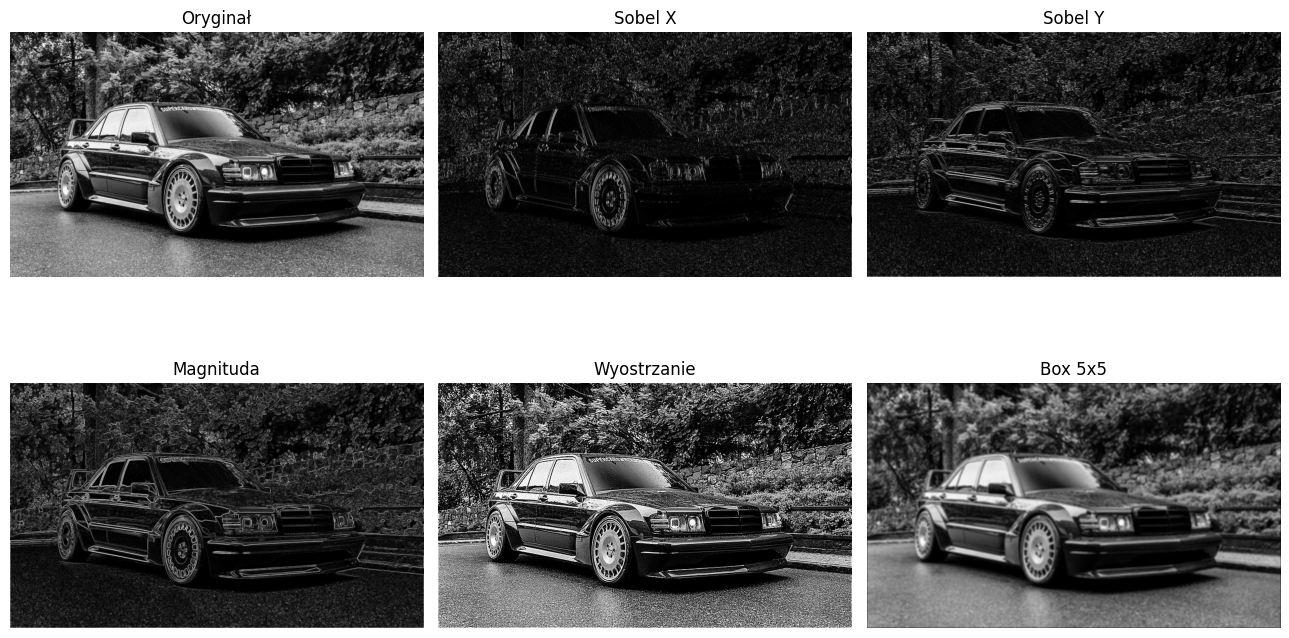

In [3]:
def kernel(values):
    return torch.tensor(values, dtype=torch.float32).view(1, 1, len(values), len(values[0]))

sobel_x = kernel([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
sobel_y = kernel([[-1, -2, -1], [0, 0, 0], [1, 2, 1]])
sharpen = kernel([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
box3 = torch.ones((1, 1, 3, 3), dtype=torch.float32) / 9
box5 = torch.ones((1, 1, 5, 5), dtype=torch.float32) / 25
g = torch.tensor([1, 4, 6, 4, 1], dtype=torch.float32)
gaussian5 = (g[:, None] * g[None, :]).view(1, 1, 5, 5) / 256

g_x = F.conv2d(gray, sobel_x, padding=1)
g_y = F.conv2d(gray, sobel_y, padding=1)
magnitude = torch.sqrt(g_x.square() + g_y.square())
results = {
    "Oryginał": gray,
    "Sobel X": g_x.abs(),
    "Sobel Y": g_y.abs(),
    "Magnituda": magnitude,
    "Wyostrzanie": F.conv2d(gray, sharpen, padding=1).clamp(0, 1),
    "Box 5x5": F.conv2d(gray, box5, padding=2)
}
fig, axs = plt.subplots(2, 3, figsize=(13, 8))
for ax, (label, tensor) in zip(axs.flat, results.items()):
    data = tensor[0, 0].detach().numpy()
    ax.imshow(data, cmap="gray", vmin=0, vmax=max(1, float(data.max())) if label in ("Sobel X", "Sobel Y", "Magnituda") else 1)
    ax.set_title(label)
    ax.axis("off")
for ax in list(axs.flat)[len(results):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


In [4]:
def out_dim(n, k, s, p, d):
    return (n + 2*p - d*(k-1) - 1) // s + 1

configs = [
    (3, 1, 1, 1),
    (3, 2, 1, 1),
    (5, 1, 2, 1),
    (3, 1, 2, 2),
    (7, 2, 3, 1)
]
rows = []
for k, s, p, d in configs:
    layer = nn.Conv2d(1, 4, kernel_size=k, stride=s, padding=p, dilation=d)
    actual = tuple(layer(gray).shape[-2:])
    theoretical = (out_dim(H, k, s, p, d), out_dim(W, k, s, p, d))
    rows.append({"k": k, "stride": s, "padding": p, "dilation": d,
                 "Wzór HxW": str(theoretical), "Conv2d HxW": str(actual),
                 "Zgodne": actual == theoretical})
tabela_wymiarow = pd.DataFrame(rows)
display(tabela_wymiarow)
assert tabela_wymiarow["Zgodne"].all()


,k,stride,padding,dilation,Wzór HxW,Conv2d HxW,Zgodne
0,3,1,1,1,"(533, 900)","(533, 900)",True
1,3,2,1,1,"(267, 450)","(267, 450)",True
2,5,1,2,1,"(533, 900)","(533, 900)",True
3,3,1,2,2,"(533, 900)","(533, 900)",True
4,7,2,3,1,"(267, 450)","(267, 450)",True


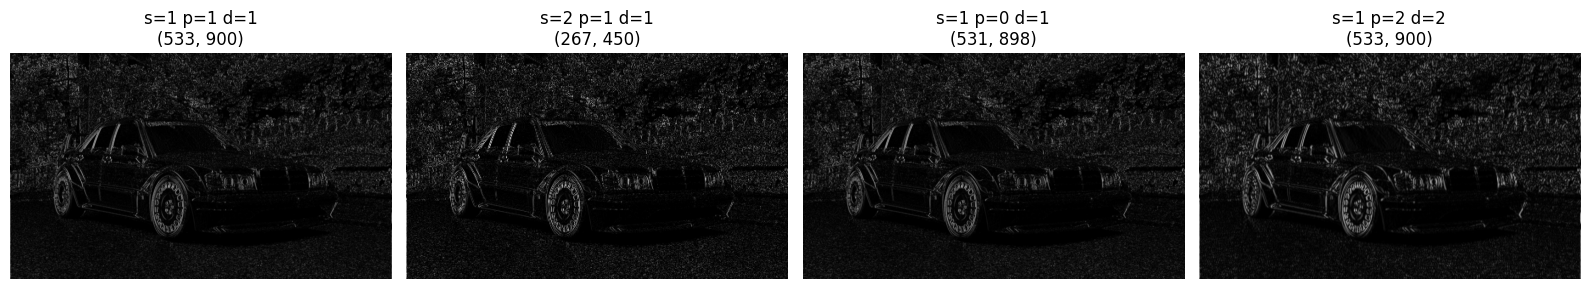

In [5]:
settings = [
    ("s=1 p=1 d=1", 1, 1, 1),
    ("s=2 p=1 d=1", 2, 1, 1),
    ("s=1 p=0 d=1", 1, 0, 1),
    ("s=1 p=2 d=2", 1, 2, 2)
]
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for ax, (label, stride, padding, dilation) in zip(axs, settings):
    y = F.conv2d(gray, sobel_x, stride=stride, padding=padding, dilation=dilation)
    ax.imshow(y[0, 0].abs().numpy(), cmap="gray", vmin=0, vmax=4)
    ax.set_title(f"{label}\n{tuple(y.shape[-2:])}")
    ax.axis("off")
plt.tight_layout()
plt.show()


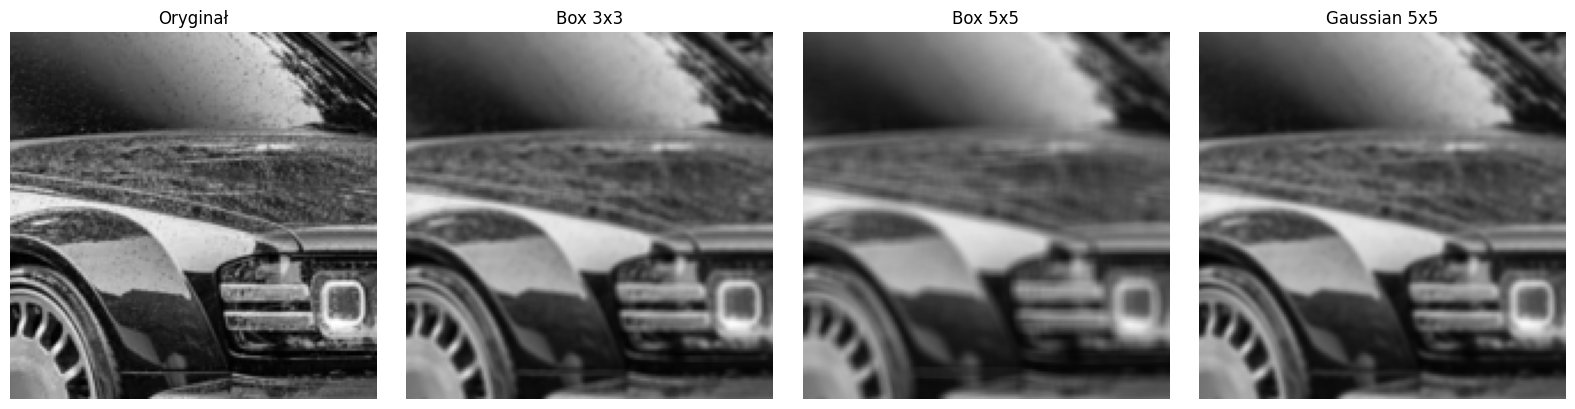

Porównany fragment: x = (370, 530) y = (186, 346)


In [6]:
blurred = {
    "Oryginał": gray,
    "Box 3x3": F.conv2d(gray, box3, padding=1),
    "Box 5x5": F.conv2d(gray, box5, padding=2),
    "Gaussian 5x5": F.conv2d(gray, gaussian5, padding=2)
}
ch, cw = min(160, H), min(160, W)
y0, x0 = (H - ch) // 2, (W - cw) // 2
fig, axs = plt.subplots(1, 4, figsize=(16, 4))
for ax, (label, tensor) in zip(axs, blurred.items()):
    crop = tensor[0, 0, y0:y0+ch, x0:x0+cw].detach().numpy()
    ax.imshow(crop, cmap="gray", vmin=0, vmax=1)
    ax.set_title(label)
    ax.axis("off")
plt.tight_layout()
plt.show()
print("Porównany fragment: x =", (x0, x0+cw), "y =", (y0, y0+ch))


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 134MB/s]


Wejście: (1, 3, 224, 224) Mapy cech: (64, 112, 112)


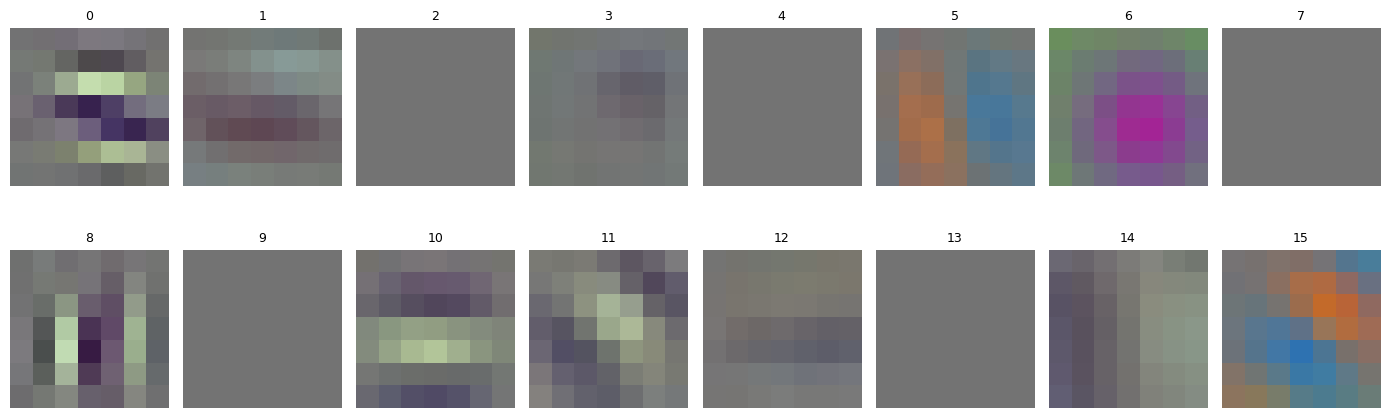

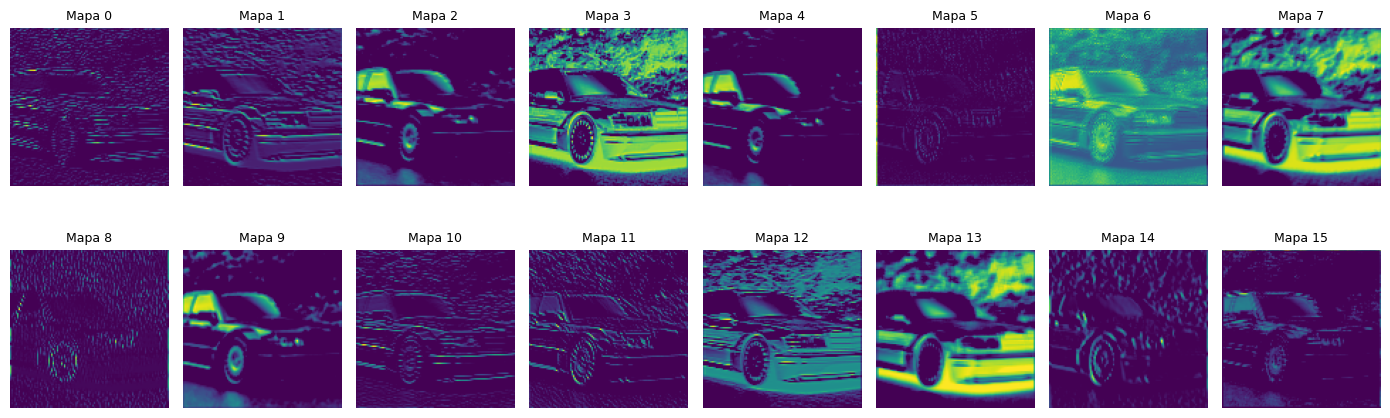

In [7]:
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights).to(device).eval()
rgb_pil = pil.convert("RGB")
preprocess = weights.transforms()
x = preprocess(rgb_pil).unsqueeze(0).to(device)
with torch.inference_mode():
    maps = torch.relu(model.conv1(x))[0].cpu()
print("Wejście:", tuple(x.shape), "Mapy cech:", tuple(maps.shape))
filters = model.conv1.weight.detach().cpu()
min_f, max_f = filters.min(), filters.max()
filters_vis = (filters - min_f) / (max_f - min_f + 1e-8)
fig, axs = plt.subplots(2, 8, figsize=(14, 5))
for idx, ax in enumerate(axs.flat):
    ax.imshow(filters_vis[idx].permute(1, 2, 0).numpy())
    ax.axis("off")
    ax.set_title(str(idx), fontsize=9)
plt.tight_layout()
plt.show()
fig, axs = plt.subplots(2, 8, figsize=(14, 5))
for idx, ax in enumerate(axs.flat):
    ax.imshow(maps[idx].numpy(), cmap="viridis")
    ax.set_title(f"Mapa {idx}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()


In [8]:
print("Rozmiar obrazu:", (H, W))
print("Parametry Conv2d:", tabela_wymiarow.to_string(index=False))
print("Porównanie rozmycia: Box 3x3, Box 5x5, Gaussian 5x5")
print("Mapy ResNet-18:", tuple(maps.shape))


Rozmiar obrazu: (533, 900)
Parametry Conv2d:  k  stride  padding  dilation   Wzór HxW Conv2d HxW  Zgodne
 3       1        1         1 (533, 900) (533, 900)    True
 3       2        1         1 (267, 450) (267, 450)    True
 5       1        2         1 (533, 900) (533, 900)    True
 3       1        2         2 (533, 900) (533, 900)    True
 7       2        3         1 (267, 450) (267, 450)    True
Porównanie rozmycia: Box 3x3, Box 5x5, Gaussian 5x5
Mapy ResNet-18: (64, 112, 112)
